# Explore Stage — Facial Expression Recognition (Smile / Neutral / Sad)

Companion to `obtain_fer.ipynb`. This notebook **only reads the CSVs that Obtain writes**
(`manifest.csv`, `rejected_images.csv`, `geometric_features.csv`, `landmark_features.csv`,
`landmark_index.csv`) and turns them into quick diagnostic graphs.

No images, no MediaPipe, no OpenCV: it runs in seconds and is safe to re-run after every
Obtain run. Figures are saved as PNG at 300 dpi in `outputs/figures/`, the same
`savefig` convention used by `OSEMN/explore/*.py`.

**Before running:** run `obtain_fer.ipynb`, or point `OUTPUTS_DIR` (cell 0) at the
`output_dir` used there.

## What each section answers

| § | Graph | Question it answers for FER |
|---|---|---|
| 2 | funnel | how many images survive each ingestion gate? |
| 3 | label balance | are smile / neutral / sad balanced? how much is unlabeled? |
| 4 | source & subject | is the dataset dominated by one person or one source? |
| 5 | rejections | why are images discarded (blur, exposure, resolution)? |
| 6-7 | quality | are the quality gates biased against one class? |
| 8 | resolution | how small are the faces the model will have to read? |
| 9-11 | geometry | do EAR / MAR / mouth features separate the 3 classes? |
| 12 | correlation | which geometric features are redundant (`|r| > 0.8`)? |
| 13-14 | landmarks | mean face per class, and which landmarks move between classes |
| 15 | scale | `iod_px` distribution and landmark-table completeness |
| 16 | audit | the numbers worth quoting before moving to Scrub |

**Reading reminder (decision D3 in Obtain):** every distance is normalized by the
inter-ocular distance (IOD), so values are comparable across image sizes and camera
distances. `mouth_curvature` negative ≈ mouth corners up, i.e. smile-like. Labels are
*harvested* from folder/file names only, so `unlabeled` rows are expected.


## 0. Setup

Everything the rest of the notebook needs: paths, the shared class colours, a
`save_fig` helper and the thresholds mirrored from `obtain_fer.ipynb`'s `CONFIG`
(D6: blur < 100, brightness outside 40-220, short side < 64 px).


In [1]:
# =============================================================================
# Setup — imports, paths, shared colours and plotting helpers
# =============================================================================
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

# Obtain outputs: same defaults as obtain_fer.ipynb (CONFIG["output_dir"])
OUTPUTS_DIR = Path("./outputs")
FIGURES_DIR = OUTPUTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Three-class problem, same class names/order as obtain_fer.CLASS_NAMES
CLASS_NAMES = ("smile", "neutral", "sad")
UNLABELED = "unlabeled"
LABEL_COLORS = {
    "smile": "#2ca02c",
    "neutral": "#1f77b4",
    "sad": "#9467bd",
    UNLABELED: "#7f7f7f",
}

# Ingestion thresholds, mirrored from obtain_fer.CONFIG (D6)
BLUR_MIN = 100.0
BRIGHT_LOW, BRIGHT_HIGH = 40.0, 220.0
MIN_SIDE_PX = 64

# Canonical geometric columns (order copied from obtain_fer.GEOMETRIC_FEATURE_ORDER)
GEOMETRIC_FEATURES = [
    "ear_left", "ear_right", "mar", "mouth_width", "mouth_height",
    "brow_eye_distance_left", "brow_eye_distance_right", "mouth_curvature",
    "nose_to_mouth_corner_left", "nose_to_mouth_corner_right",
    "face_width", "face_height",
]

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
})


def save_fig(fig, name):
    # Same convention as OSEMN/explore/*.py: PNG at 300 dpi, and shown inline.
    path = FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"figure saved -> {path}")
    plt.show()


def label_color(label):
    return LABEL_COLORS.get(str(label), "#d62728")


def boxplot_by_class(ax, dataframe, column, class_list, ylabel):
    # Manual boxplot (no seaborn): one box per class, no outliers to keep it readable.
    data = [dataframe.loc[dataframe["label"] == c, column].dropna().values for c in class_list]
    if not any(len(values) for values in data):
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        return
    box = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, c in zip(box["boxes"], class_list):
        patch.set_facecolor(label_color(c))
        patch.set_alpha(0.75)
    ax.set_xticks(range(1, len(class_list) + 1), class_list)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)


print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)
print("reading Obtain outputs from:", OUTPUTS_DIR.resolve())


pandas 3.0.6 | numpy 1.26.4 | matplotlib 3.11.2
reading Obtain outputs from: C:\Users\felip\Downloads\Github\Facial-Expression-Recognition\OSEMN\outputs


## 1. Load the Obtain outputs

Five CSVs, all written by the same Obtain run. The cell also:

* turns the empty strings Obtain writes for "no label" / "no rejection" into readable
  values (`unlabeled`, `""`),
* derives `accepted`, `short_side`, `aspect_ratio` and `megapixels` from the manifest,
* joins the quality metrics (`blur_score`, `brightness`, `width`, `height`) onto the
  geometric table, because those metrics only live in `manifest.csv`,
* asserts that `rejected_images.csv` and `manifest.csv` agree — they must come from the
  same run, otherwise every count below is meaningless.


In [2]:
# =============================================================================
# 1. Load the tables written by obtain_fer.ipynb
# =============================================================================
FILES = {
    "manifest": "manifest.csv",
    "rejected": "rejected_images.csv",
    "geometric": "geometric_features.csv",
    "landmarks": "landmark_features.csv",
    "landmark_index": "landmark_index.csv",
}

missing = [name for name, file in FILES.items() if not (OUTPUTS_DIR / file).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing Obtain outputs in {OUTPUTS_DIR.resolve()}: {missing}. "
        "Run obtain_fer.ipynb first, or point OUTPUTS_DIR to its output_dir."
    )

# Column order documented in obtain_fer.ipynb (§14). Used to rebuild empty/missing
# tables: when every image is rejected, Obtain writes feature CSVs with no header at all.
REQUIRED_COLUMNS = {
    "manifest": ["image_path", "source", "subject_id", "label", "width", "height",
                 "face_found", "n_landmarks", "blur_score", "brightness", "rejected_reason"],
    "rejected": ["image_path", "source", "subject_id", "label", "width", "height",
                 "blur_score", "brightness", "rejected_reason"],
    "geometric": ["image_path", "source", "subject_id", "label", "face_found", "n_faces",
                  "iod_px"] + GEOMETRIC_FEATURES + ["error"],
    "landmarks": ["image_path", "source", "subject_id", "label", "face_found",
                  "n_landmarks", "error"],
    "landmark_index": ["column_name", "face_mesh_index", "axis"],
}


def read_table(name, path):
    try:
        table = pd.read_csv(path)
    except pd.errors.EmptyDataError:  # empty table: no header was written at all
        print(f"warning: {path.name} is empty (nothing passed Obtain)")
        table = pd.DataFrame()
    columns = list(dict.fromkeys(REQUIRED_COLUMNS[name] + list(table.columns)))
    return table.reindex(columns=columns)


tables = {name: read_table(name, OUTPUTS_DIR / file) for name, file in FILES.items()}

manifest = tables["manifest"]
rejected = tables["rejected"]
geometric = tables["geometric"]
landmarks = tables["landmarks"]
landmark_index = tables["landmark_index"]

# --- clean the empty strings Obtain writes for "nothing here" ---------------
manifest["rejected_reason"] = manifest["rejected_reason"].fillna("")
manifest["face_found"] = manifest["face_found"].fillna(False).astype(bool)
for df in (manifest, geometric, landmarks):
    df["label"] = df["label"].fillna(UNLABELED)
geometric["face_found"] = geometric["face_found"].fillna(False).astype(bool)
geometric["n_faces"] = geometric["n_faces"].fillna(0).astype(int)

# --- derived columns used by the plots below --------------------------------
manifest["accepted"] = manifest["rejected_reason"] == ""
manifest["short_side"] = manifest[["width", "height"]].min(axis=1)
manifest["aspect_ratio"] = manifest["width"] / manifest["height"]
manifest["megapixels"] = manifest["width"] * manifest["height"] / 1e6

# Quality metrics exist only in the manifest: join them onto the feature table (D10
# keeps a row in geometric_features even when no face was found).
geo = geometric.merge(
    manifest[["image_path", "blur_score", "brightness", "width", "height"]],
    on="image_path",
    how="left",
)
geo["ear_mean"] = geo[["ear_left", "ear_right"]].mean(axis=1)

# --- consistency checks -----------------------------------------------------
n_rejected_manifest = int((~manifest["accepted"]).sum())
assert len(rejected) == n_rejected_manifest, (
    f"rejected_images.csv has {len(rejected)} rows but manifest flags "
    f"{n_rejected_manifest} rejected: the tables come from different Obtain runs."
)

coord_cols = [c for c in landmarks.columns if c.startswith(("x_", "y_", "z_"))]
unmapped_cols = [c for c in coord_cols if c not in set(landmark_index["column_name"])]

print("manifest           :", manifest.shape)
print("rejected_images    :", rejected.shape)
print("geometric_features :", geometric.shape)
print("landmark_features  :", landmarks.shape, f"({len(coord_cols)} coordinate columns)")
print("landmark_index     :", landmark_index.shape,
      "| axes:", landmark_index["axis"].value_counts().to_dict())
print("coordinate columns without an index entry:", len(unmapped_cols))
manifest.head()


manifest           : (4254, 15)
rejected_images    : (265, 9)
geometric_features : (3989, 20)
landmark_features  : (3989, 963) (956 coordinate columns)
landmark_index     : (956, 3) | axes: {'x': 478, 'y': 478}
coordinate columns without an index entry: 0


,image_path,source,subject_id,label,width,height,face_found,n_landmarks,blur_score,brightness,rejected_reason,accepted,short_side,aspect_ratio,megapixels
0,data/happy/PrivateTest_10077120.jpg,happy,PrivateTest,smile,48,48,True,478,2948.684509,177.660156,,True,48,1.0,0.002304
1,data/happy/PrivateTest_10470092.jpg,happy,PrivateTest,smile,48,48,True,478,2490.379195,72.268229,,True,48,1.0,0.002304
2,data/happy/PrivateTest_10513598.jpg,happy,PrivateTest,smile,48,48,True,478,6090.828411,118.267795,,True,48,1.0,0.002304
3,data/happy/PrivateTest_10516065.jpg,happy,PrivateTest,smile,48,48,True,478,6751.581862,167.838976,,True,48,1.0,0.002304
4,data/happy/PrivateTest_10613684.jpg,happy,PrivateTest,smile,48,48,True,478,2212.090902,112.397135,,True,48,1.0,0.002304


## 2. Obtain funnel

How many images were found, how many passed the ingestion gates, and how many of those
actually produced a face. The gap between the last two bars is the real recall ceiling of
everything downstream: a face the landmark detector never saw can never be classified.

`face_found=False` rows are **kept** in the feature tables (D10), so they must be dropped
explicitly in Scrub — this graph tells you how big that drop will be.


figure saved -> outputs\figures\01_obtain_funnel.png


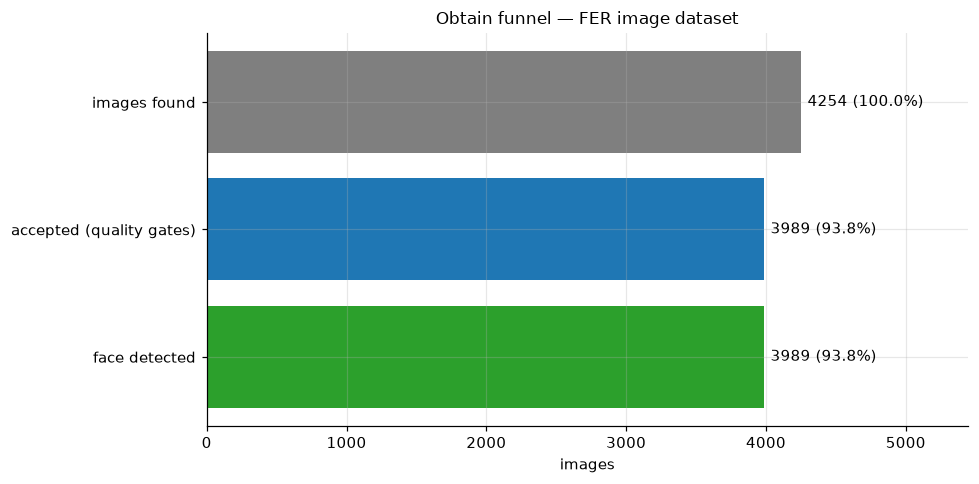

rejected = 265  |  accepted without face = 0


In [3]:
# =============================================================================
# 2. Pipeline funnel — how many images survive each Obtain gate
# =============================================================================
n_found = len(manifest)
n_accepted = int(manifest["accepted"].sum())
n_face = int(manifest.loc[manifest["accepted"], "face_found"].sum())

steps = ["images found", "accepted (quality gates)", "face detected"]
counts = [n_found, n_accepted, n_face]
shares = [c / n_found if n_found else 0.0 for c in counts]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(steps[::-1], counts[::-1], color=["#2ca02c", "#1f77b4", "#7f7f7f"])
ax.bar_label(bars, labels=[f"{c} ({s:.1%})" for c, s in zip(counts[::-1], shares[::-1])], padding=4)
ax.set_xlabel("images")
ax.set_title("Obtain funnel — FER image dataset")
ax.set_xlim(0, max(counts) * 1.28 if n_found else 1)
plt.tight_layout()
save_fig(fig, "01_obtain_funnel")

print(f"rejected = {n_found - n_accepted}  |  accepted without face = {n_accepted - n_face}")


## 3. Label balance

The first thing a 3-class model cares about. Grey bars are every image found, coloured
bars are the ones that survived the gates — the difference is what Scrub will have to fix
(or what makes a class impossible to learn).

`unlabeled` is not an error: Obtain never predicts labels, it only harvests them from
folder/file names, so team photos without a label token land here.

`classes` (computed here) is reused by every later plot so colour and order stay stable.


figure saved -> outputs\figures\02_label_balance.png


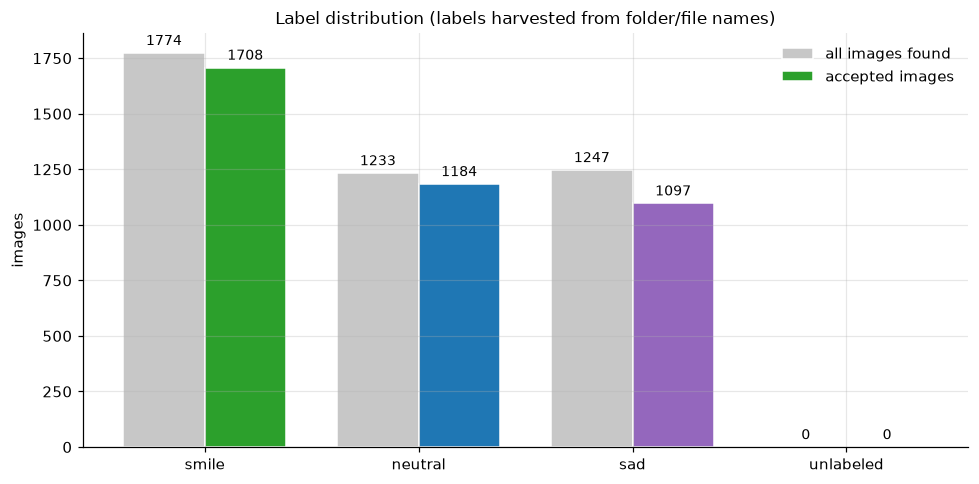

,all,accepted,accepted_%
label,,,
smile,1774,1708,42.8
neutral,1233,1184,29.7
sad,1247,1097,27.5
unlabeled,0,0,0.0


In [4]:
# =============================================================================
# 3. Label balance — the first thing a 3-class FER model cares about
# =============================================================================
# Keep the three FER classes first, then any extra label the names produced (typos included).
extras = sorted(set(manifest["label"]) - set(LABEL_COLORS))
order = list(LABEL_COLORS) + extras
classes = [c for c in order if c in set(manifest["label"])]

all_counts = manifest["label"].value_counts().reindex(order, fill_value=0)
acc_counts = manifest.loc[manifest["accepted"], "label"].value_counts().reindex(order, fill_value=0)

x = np.arange(len(order))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.5))
bars_all = ax.bar(x - width / 2, all_counts.values, width, label="all images found",
                  color="#c7c7c7", edgecolor="white")
bars_acc = ax.bar(x + width / 2, acc_counts.values, width, label="accepted images",
                  color=[label_color(c) for c in order], edgecolor="white")
ax.bar_label(bars_all, padding=3, fontsize=9)
ax.bar_label(bars_acc, padding=3, fontsize=9)
ax.set_xticks(x, order)
ax.set_ylabel("images")
ax.set_title("Label distribution (labels harvested from folder/file names)")
ax.legend(frameon=False)
plt.tight_layout()
save_fig(fig, "02_label_balance")

total_acc = max(int(acc_counts.sum()), 1)
summary = pd.DataFrame({"all": all_counts, "accepted": acc_counts})
summary["accepted_%"] = (summary["accepted"] / total_acc * 100).round(1)
summary


## 4. Sources and subjects

Two different leakage risks:

* **`source`** — a public dataset (KDEF, FER2013, ...) and the team photos have very
  different cameras, lighting and pose statistics. If one source dominates, the model can
  learn *the source* instead of the expression.
* **`subject_id`** — if one volunteer supplies most images, a random train/test split will
  put the same face on both sides. Scrub should split **by subject**, so the class mix per
  subject (second figure) shows where such a split would hurt.


figure saved -> outputs\figures\03_source_subject_coverage.png


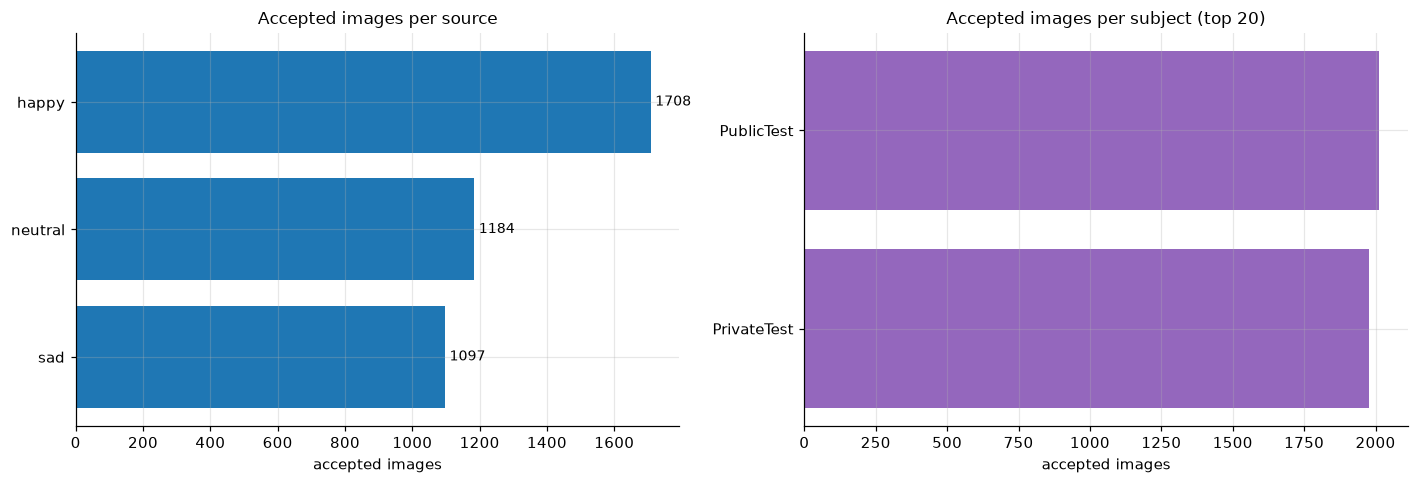

In [5]:
# =============================================================================
# 4a. Where do the accepted images come from?
# =============================================================================
accepted_rows = manifest.loc[manifest["accepted"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

source_counts = accepted_rows["source"].fillna("(unknown)").value_counts()
axes[0].barh(source_counts.index[::-1].astype(str), source_counts.values[::-1], color="#1f77b4")
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
axes[0].set_xlabel("accepted images")
axes[0].set_title("Accepted images per source")

subject_counts = accepted_rows["subject_id"].fillna("(unknown)").value_counts().head(20)
if subject_counts.empty:
    axes[1].text(0.5, 0.5, "no accepted images", ha="center", va="center",
                 transform=axes[1].transAxes)
    axes[1].set_axis_off()
else:
    axes[1].barh(subject_counts.index[::-1].astype(str), subject_counts.values[::-1],
                 color="#9467bd")
    axes[1].set_xlabel("accepted images")
axes[1].set_title("Accepted images per subject (top 20)")

plt.tight_layout()
save_fig(fig, "03_source_subject_coverage")


figure saved -> outputs\figures\04_class_mix_per_subject.png


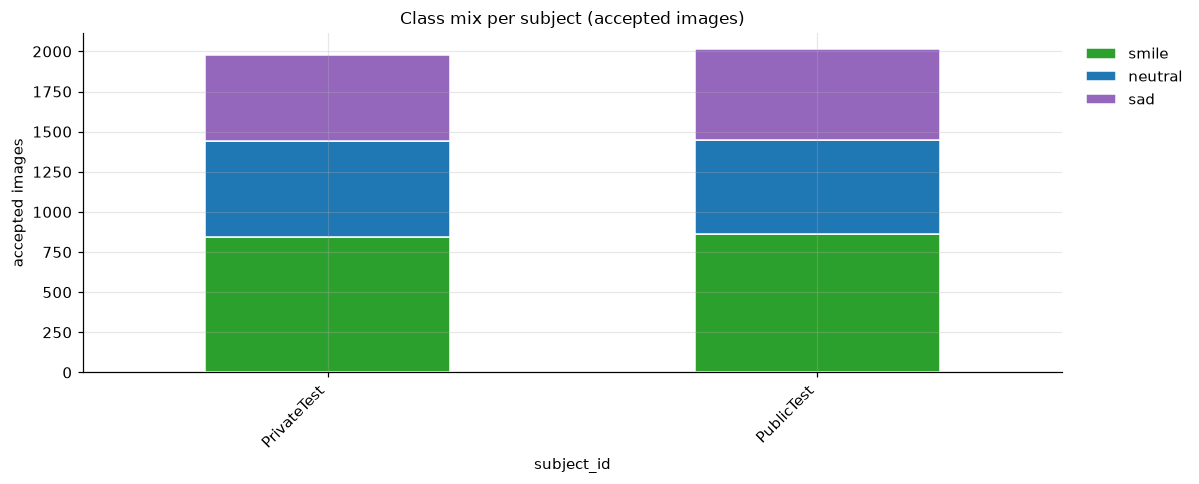

label,smile,neutral,sad
subject_id,,,
PrivateTest,844,599,533
PublicTest,864,585,564


In [6]:
# =============================================================================
# 4b. Class mix per subject — where a by-subject split would hurt
# =============================================================================
pivot = (
    accepted_rows.assign(subject_id=accepted_rows["subject_id"].fillna("(unknown)"))
    .pivot_table(index="subject_id", columns="label", values="image_path",
                 aggfunc="count", fill_value=0)
)
pivot = pivot[[c for c in order if c in pivot.columns]]

if pivot.empty:
    print("no accepted images carry a subject_id — nothing to stack")
else:
    ax = pivot.plot(
        kind="bar", stacked=True, figsize=(11, 4.5),
        color=[label_color(c) for c in pivot.columns], edgecolor="white",
    )
    ax.set_xlabel("subject_id")
    ax.set_ylabel("accepted images")
    ax.set_title("Class mix per subject (accepted images)")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    save_fig(ax.figure, "04_class_mix_per_subject")
pivot


## 5. Why are images rejected?

Obtain writes one string per rejected image, and an image can trip several gates at once
(`blurry: laplacian_var=… ; too dark: mean_gray=…`). The cell splits each reason on `;`
and keeps only the gate name, so the bars stay comparable. Because of that, the bars can
sum to more than the number of rejected images — that is expected.

A dataset that loses most images to *low resolution* is telling you the source images are
too small for FaceMesh (FER2013 at 48×48 is exactly this case); one that loses them to
*blur* is telling you the capture protocol needs fixing, not the model.


figure saved -> outputs\figures\05_rejection_reasons.png


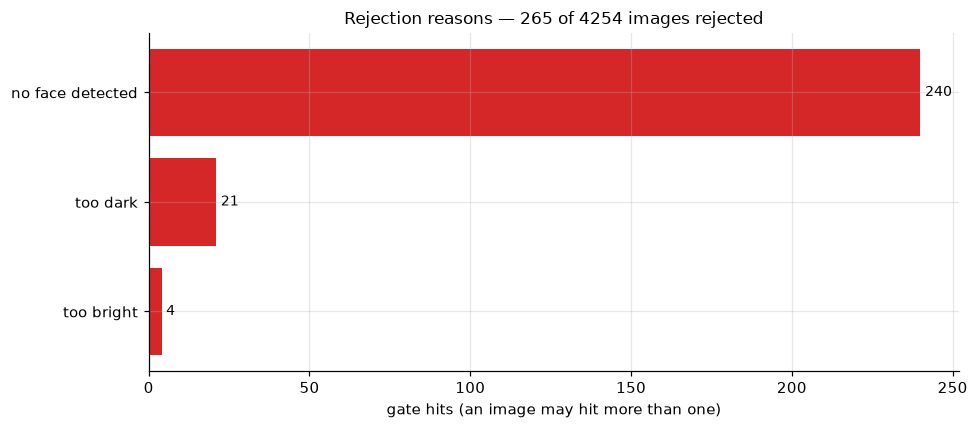

rejected_reason
no face detected    240
too dark             21
too bright            4
Name: images, dtype: int64

In [7]:
# =============================================================================
# 5. Rejection reasons, grouped by gate name
# =============================================================================
n_rejected = int((~manifest["accepted"]).sum())

reason_gates = (
    manifest.loc[~manifest["accepted"], "rejected_reason"]
    .str.split(";")
    .explode()
    .str.split(":")
    .str[0]
    .str.strip()
    .value_counts()
)

fig, ax = plt.subplots(figsize=(9, 4))
if reason_gates.empty:
    ax.text(0.5, 0.5, "no rejected images", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
else:
    ax.barh(reason_gates.index[::-1], reason_gates.values[::-1], color="#d62728")
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set_xlabel("gate hits (an image may hit more than one)")
ax.set_title(f"Rejection reasons — {n_rejected} of {len(manifest)} images rejected")
plt.tight_layout()
save_fig(fig, "05_rejection_reasons")

reason_gates.rename("images")


## 6. Quality gates: blur and brightness

The distributions behind the gates, with the thresholds drawn in. Values left of the
dashed line (blur) or outside the band (brightness) were rejected at ingestion.

Reading tip: a mass of images just *below* the blur threshold is harmless, but a
bimodal blur distribution usually means two capture protocols (two sources, or a phone
plus a webcam), which is a Scrub/split concern.


figure saved -> outputs\figures\06_quality_distributions.png


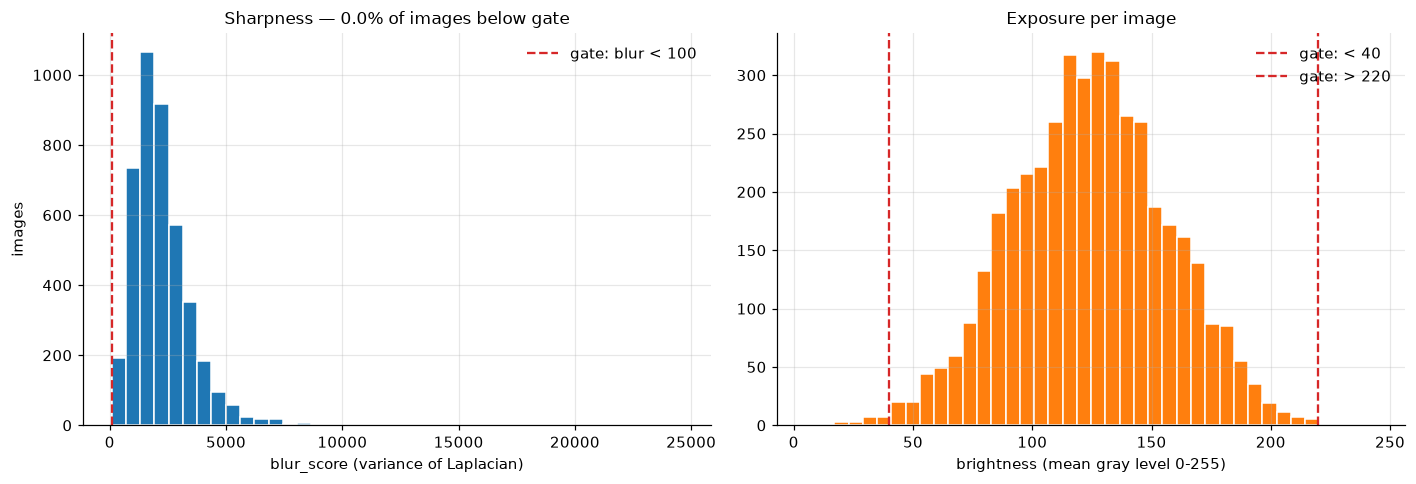

In [8]:
# =============================================================================
# 6. Blur and brightness distributions with the ingestion gates
# =============================================================================
blur = manifest["blur_score"].dropna()
brightness = manifest["brightness"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(blur, bins=40, color="#1f77b4", edgecolor="white")
axes[0].axvline(BLUR_MIN, color="#d62728", ls="--", lw=1.5, label=f"gate: blur < {BLUR_MIN:g}")
axes[0].set_xlabel("blur_score (variance of Laplacian)")
axes[0].set_ylabel("images")
axes[0].set_title(f"Sharpness — {100 * (blur < BLUR_MIN).mean():.1f}% of images below gate")
axes[0].legend(frameon=False)

axes[1].hist(brightness, bins=40, color="#ff7f0e", edgecolor="white")
axes[1].axvline(BRIGHT_LOW, color="#d62728", ls="--", lw=1.5, label=f"gate: < {BRIGHT_LOW:g}")
axes[1].axvline(BRIGHT_HIGH, color="#d62728", ls="--", lw=1.5, label=f"gate: > {BRIGHT_HIGH:g}")
axes[1].set_xlabel("brightness (mean gray level 0-255)")
axes[1].set_title("Exposure per image")
axes[1].legend(frameon=False)

plt.tight_layout()
save_fig(fig, "06_quality_distributions")


## 7. Are the quality gates biased against a class?

Comparing sharpness and exposure **per class** matters because a gate that removes
"too dark" images will systematically remove whatever class was photographed in dim light
— and the model then fails on exactly that class at test time. Ideally the three boxes
overlap; a visibly lower `sad` box is a warning to check the capture protocol before
trusting any accuracy number.


figure saved -> outputs\figures\07_quality_by_class.png


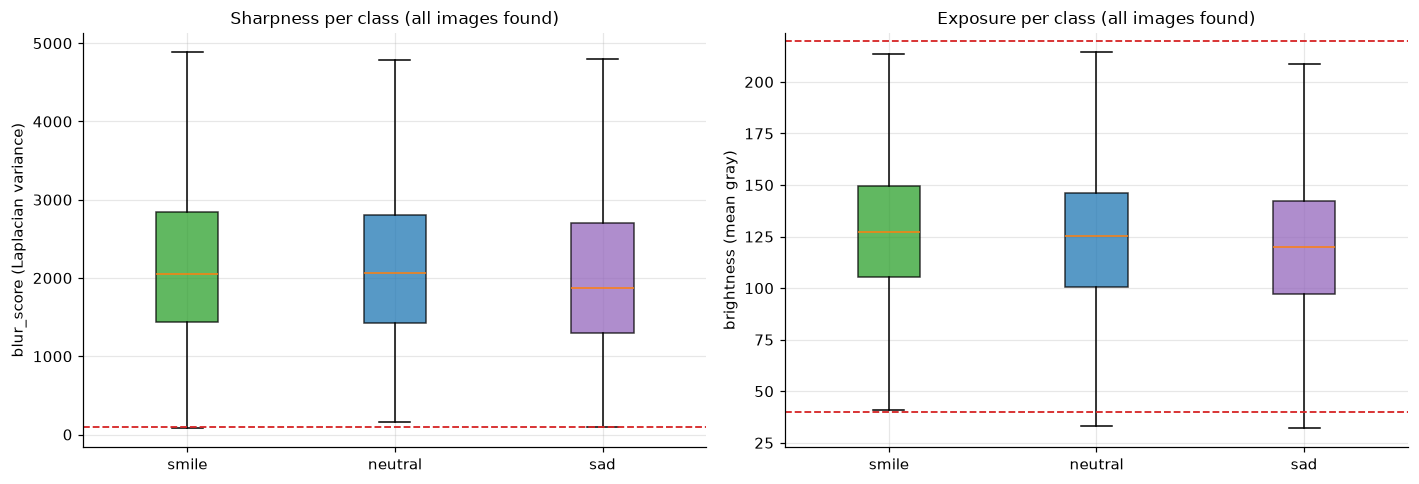

,blur_score,brightness
label,,
neutral,2063.2,125.2
sad,1872.1,120.1
smile,2045.6,127.4


In [9]:
# =============================================================================
# 7. Quality per class — a gate that hits one class harder biases the dataset
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
boxplot_by_class(axes[0], manifest, "blur_score", classes, "blur_score (Laplacian variance)")
boxplot_by_class(axes[1], manifest, "brightness", classes, "brightness (mean gray)")
axes[0].set_title("Sharpness per class (all images found)")
axes[1].set_title("Exposure per class (all images found)")
axes[0].axhline(BLUR_MIN, color="#d62728", ls="--", lw=1.2)
axes[1].axhline(BRIGHT_LOW, color="#d62728", ls="--", lw=1.2)
axes[1].axhline(BRIGHT_HIGH, color="#d62728", ls="--", lw=1.2)
plt.tight_layout()
save_fig(fig, "07_quality_by_class")

manifest.groupby("label")[["blur_score", "brightness"]].median().round(1)


## 8. Resolution

`min(width, height)` is the gate Obtain enforces at 64 px, but 64 px is only the point
where FaceMesh stops working — it is not a comfortable size. This graph shows how much
headroom the dataset has: public sets such as FER2013 (48×48) would be rejected wholesale
and must be upscaled before Obtain, while KDEF-style photos (≈560×760) are fine.


figure saved -> outputs\figures\08_resolution.png


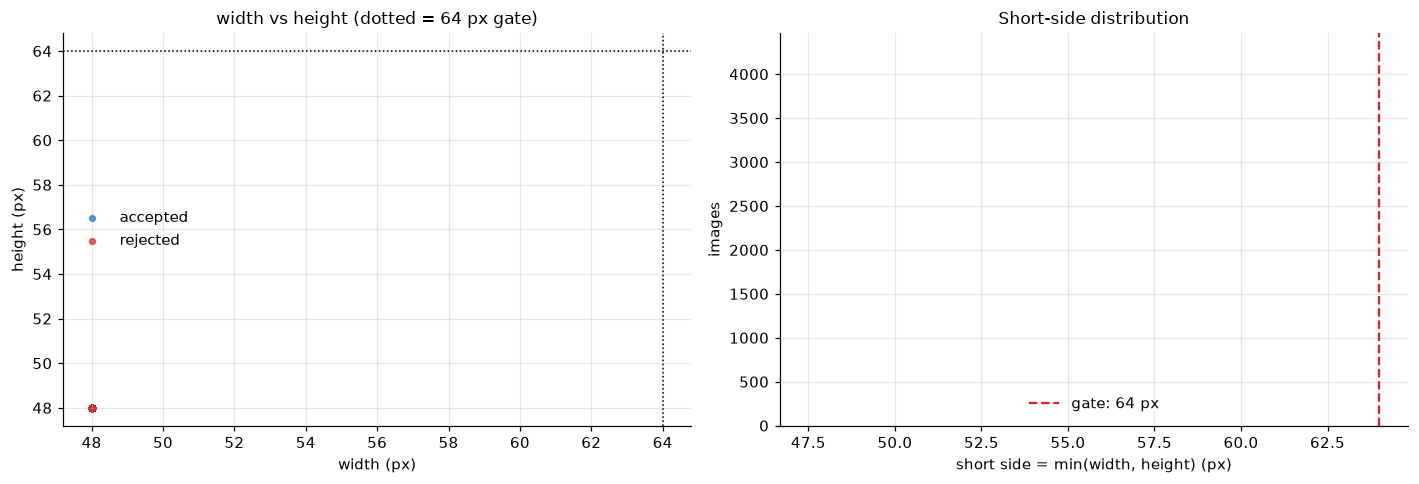

,count,min,50%,max
source,,,,
happy,1774.0,48.0,48.0,48.0
neutral,1233.0,48.0,48.0,48.0
sad,1247.0,48.0,48.0,48.0


In [10]:
# =============================================================================
# 8. Resolution — how small are the images we ask the model to read?
# =============================================================================
rejected_rows = manifest.loc[~manifest["accepted"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(accepted_rows["width"], accepted_rows["height"], s=14, alpha=0.7,
                color="#1f77b4", label="accepted")
axes[0].scatter(rejected_rows["width"], rejected_rows["height"], s=14, alpha=0.7,
                color="#d62728", label="rejected")
axes[0].axvline(MIN_SIDE_PX, ls=":", color="black", lw=1)
axes[0].axhline(MIN_SIDE_PX, ls=":", color="black", lw=1)
axes[0].set_xlabel("width (px)")
axes[0].set_ylabel("height (px)")
axes[0].set_title(f"width vs height (dotted = {MIN_SIDE_PX} px gate)")
axes[0].legend(frameon=False)

axes[1].hist(manifest["short_side"].dropna(), bins=40, color="#2ca02c", edgecolor="white")
axes[1].axvline(MIN_SIDE_PX, color="#d62728", ls="--", lw=1.5, label=f"gate: {MIN_SIDE_PX} px")
axes[1].set_xlabel("short side = min(width, height) (px)")
axes[1].set_ylabel("images")
axes[1].set_title("Short-side distribution")
axes[1].legend(frameon=False)

plt.tight_layout()
save_fig(fig, "08_resolution")

manifest.groupby("source", dropna=False)["short_side"].describe()[["count", "min", "50%", "max"]].round(1)


## 9. Do the geometric features separate the three classes?

One box per class and per feature, computed on the accepted images that actually produced
a face (Approach A of Obtain, `geometric_features.csv`).

What a usable FER feature looks like: `mouth_curvature` (negative = corners up) and
`mouth_width` should move between `smile` and `neutral`; `mar` (mouth aspect ratio) and
`ear_mean` (eye aspect ratio) should stay comparatively flat, because people do not open
their mouth or their eyes to smile. If the boxes overlap almost completely, classical
geometry is not enough and the CNN route (Approach B / `landmark_features.csv`) is the
better bet.


figure saved -> outputs\figures\09_geometry_by_class.png


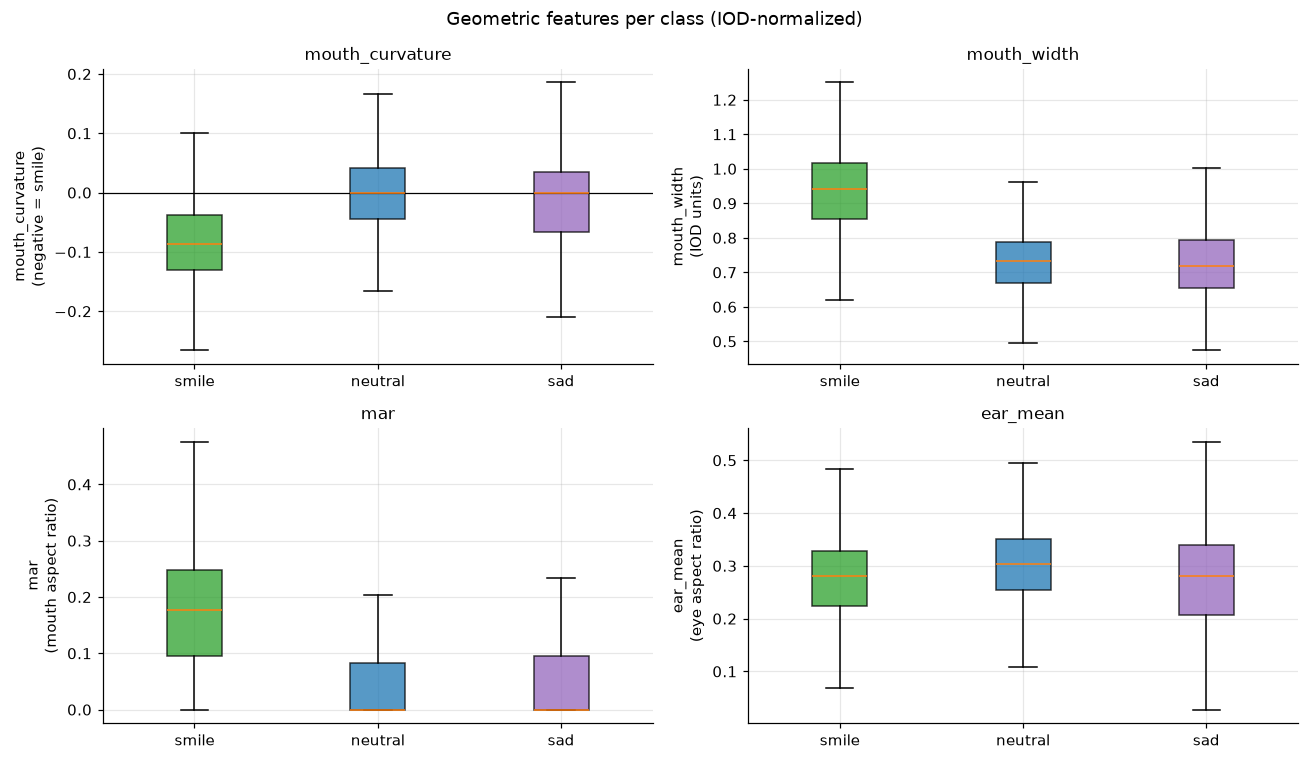

,mouth_curvature,mouth_width,mar,ear_mean
label,,,,
neutral,0.000,0.732,0.000,0.303
sad,0.000,0.719,0.000,0.280
smile,-0.087,0.943,0.176,0.280


In [11]:
# =============================================================================
# 9. Geometric features per class (IOD-normalized, Approach A)
# =============================================================================
FEATURES = ["mouth_curvature", "mouth_width", "mar", "ear_mean"]
FEATURE_LABELS = {
    "mouth_curvature": "mouth_curvature\n(negative = smile)",
    "mouth_width": "mouth_width\n(IOD units)",
    "mar": "mar\n(mouth aspect ratio)",
    "ear_mean": "ear_mean\n(eye aspect ratio)",
}

geo_classes = [c for c in classes if c in set(geo["label"])]

if geo.empty or not geo_classes:
    print("geometric_features.csv has no accepted rows to plot")
else:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, feature in zip(axes.ravel(), FEATURES):
        boxplot_by_class(ax, geo, feature, geo_classes, FEATURE_LABELS[feature])
        ax.set_title(feature)
        if feature == "mouth_curvature":
            ax.axhline(0, color="black", lw=0.8)  # negative = smile-like
    plt.suptitle("Geometric features per class (IOD-normalized)")
    plt.tight_layout()
    save_fig(fig, "09_geometry_by_class")

geo.groupby("label")[FEATURES].median().round(3)


## 10. Eye openness vs mouth openness

The same scatter style as `OSEMN/explore/explore.py`, but coloured by class instead of by
blink state. Points are accepted images with a detected face.

A good sign is three clouds that are shifted along the y-axis (`mar`) or x-axis (`ear_mean`)
rather than completely mixed. Blinks also show up here: a `smile` photo caught mid-blink
has a low `ear_mean`, so a few low-EAR points inside a class are usually noise, not
structure.


figure saved -> outputs\figures\10_ear_vs_mar.png


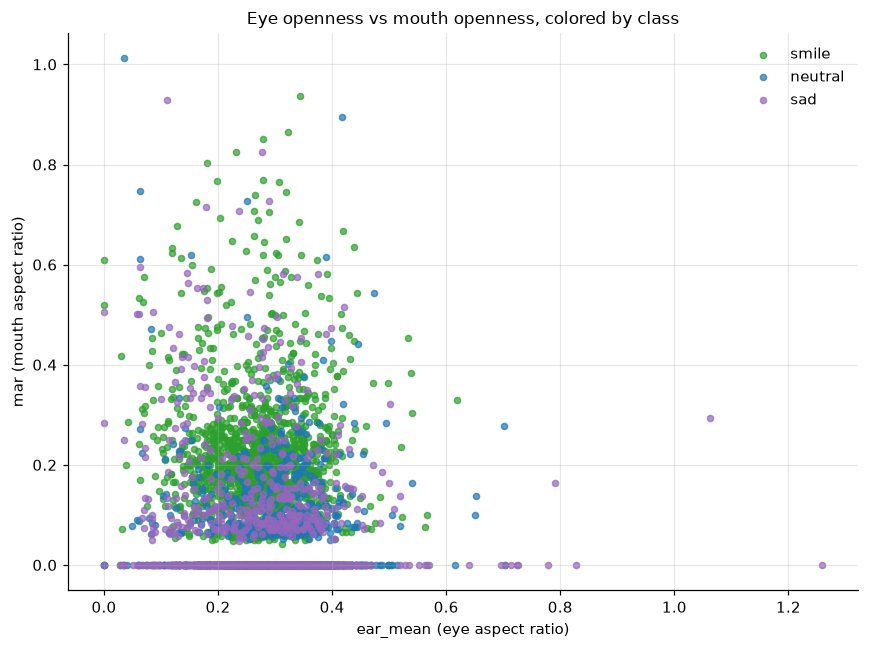

In [12]:
# =============================================================================
# 10. EAR vs MAR — eye openness against mouth openness, colored by class
# =============================================================================
fig, ax = plt.subplots(figsize=(8, 6))
for c in geo_classes:
    sub = geo[geo["label"] == c]
    ax.scatter(sub["ear_mean"], sub["mar"], s=16, alpha=0.7, color=label_color(c), label=c)
ax.set_xlabel("ear_mean (eye aspect ratio)")
ax.set_ylabel("mar (mouth aspect ratio)")
ax.set_title("Eye openness vs mouth openness, colored by class")
ax.legend(frameon=False)
plt.tight_layout()
save_fig(fig, "10_ear_vs_mar")


## 11. Smile signature: wide mouth + corners up

This is the single most interpretable plot for the smile class. `smile` points should sit
to the right (bigger `mouth_width`) and below zero (`mouth_curvature` negative = corners
raised). `sad` should be tighter and above the line, `neutral` in between.

The horizontal line at 0 is the natural decision boundary for `mouth_curvature`; if the
classes do not separate across it, the landmark detector is probably fitted loosely
(profile faces, low resolution) rather than the expressions being ambiguous.


figure saved -> outputs\figures\11_smile_signature.png


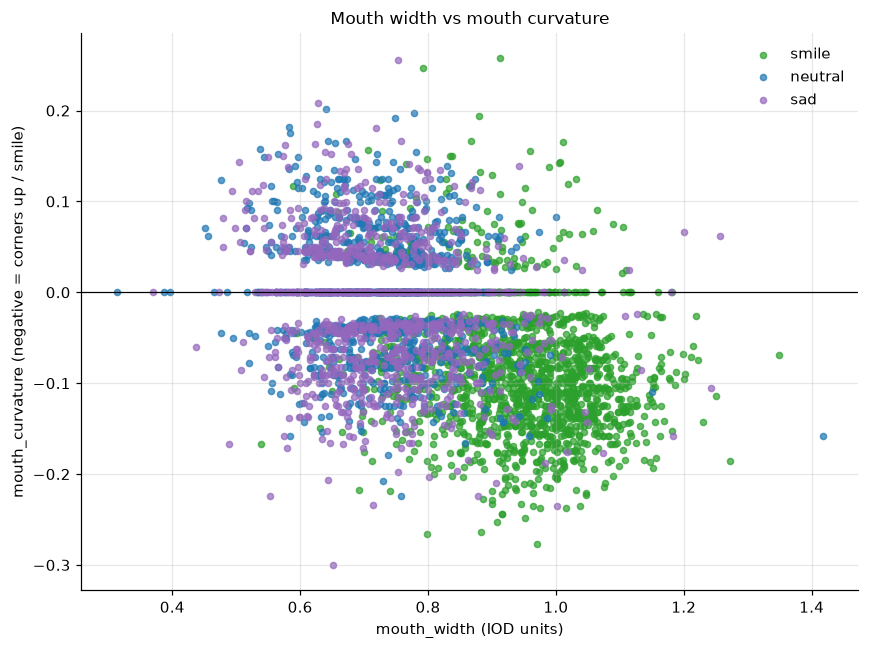

In [13]:
# =============================================================================
# 11. Smile signature — wide mouth and raised corners
# =============================================================================
fig, ax = plt.subplots(figsize=(8, 6))
for c in geo_classes:
    sub = geo[geo["label"] == c]
    ax.scatter(sub["mouth_width"], sub["mouth_curvature"], s=16, alpha=0.7,
               color=label_color(c), label=c)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("mouth_width (IOD units)")
ax.set_ylabel("mouth_curvature (negative = corners up / smile)")
ax.set_title("Mouth width vs mouth curvature")
ax.legend(frameon=False)
plt.tight_layout()
save_fig(fig, "11_smile_signature")


## 12. Feature redundancy

A correlation matrix of the 12 geometric features. Pairs with `|r| > 0.8` carry nearly the
same information (typically `ear_left`/`ear_right`, and `face_width` against the mouth
distances), which matters if the Model stage uses a linear model or a distance-based
classifier — duplicated features inflate their weight for no gain.

Values are computed on accepted images with a detected face only; NaN rows are ignored
pairwise by pandas.


figure saved -> outputs\figures\12_feature_correlation.png


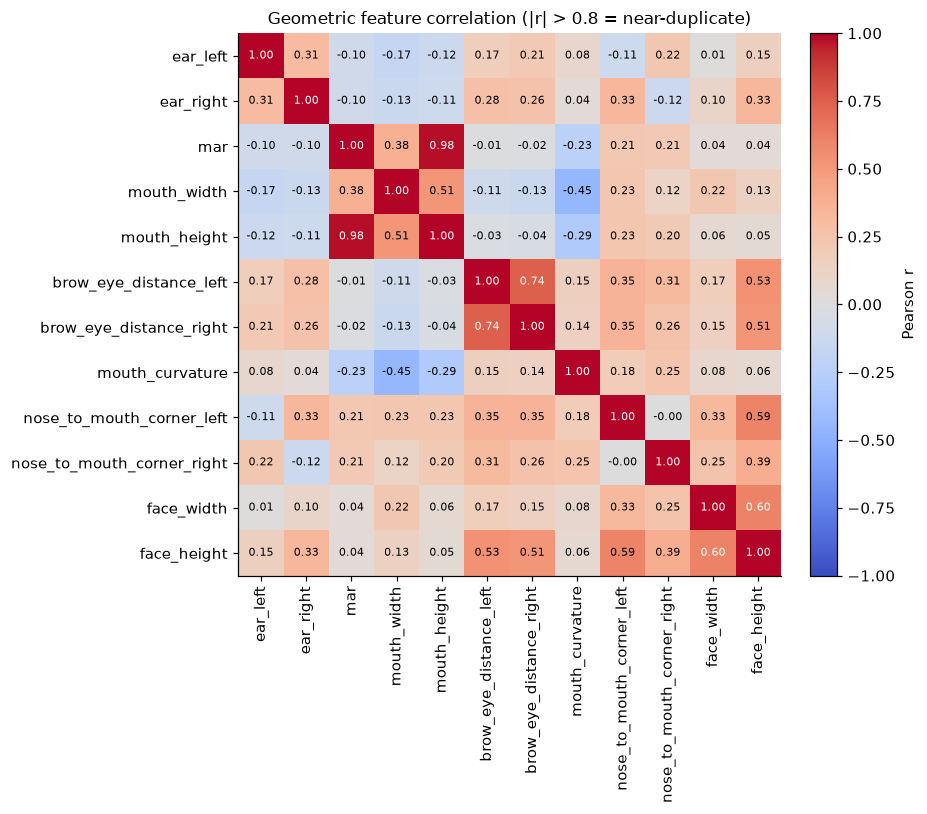

,ear_left,ear_right,mar,mouth_width,mouth_height,brow_eye_distance_left,brow_eye_distance_right,mouth_curvature,nose_to_mouth_corner_left,nose_to_mouth_corner_right,face_width,face_height
ear_left,1.00,0.31,-0.10,-0.17,-0.12,0.17,0.21,0.08,-0.11,0.22,0.01,0.15
ear_right,0.31,1.00,-0.10,-0.13,-0.11,0.28,0.26,0.04,0.33,-0.12,0.10,0.33
mar,-0.10,-0.10,1.00,0.38,0.98,-0.01,-0.02,-0.23,0.21,0.21,0.04,0.04
mouth_width,-0.17,-0.13,0.38,1.00,0.51,-0.11,-0.13,-0.45,0.23,0.12,0.22,0.13
mouth_height,-0.12,-0.11,0.98,0.51,1.00,-0.03,-0.04,-0.29,0.23,0.20,0.06,0.05
brow_eye_distance_left,0.17,0.28,-0.01,-0.11,-0.03,1.00,0.74,0.15,0.35,0.31,0.17,0.53
brow_eye_distance_right,0.21,0.26,-0.02,-0.13,-0.04,0.74,1.00,0.14,0.35,0.26,0.15,0.51
mouth_curvature,0.08,0.04,-0.23,-0.45,-0.29,0.15,0.14,1.00,0.18,0.25,0.08,0.06
nose_to_mouth_corner_left,-0.11,0.33,0.21,0.23,0.23,0.35,0.35,0.18,1.00,-0.00,0.33,0.59
nose_to_mouth_corner_right,0.22,-0.12,0.21,0.12,0.20,0.31,0.26,0.25,-0.00,1.00,0.25,0.39


In [14]:
# =============================================================================
# 12. Redundancy — Pearson correlation of the geometric features
# =============================================================================
corr = geo[GEOMETRIC_FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(value) > 0.6 else "black")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
ax.set_title("Geometric feature correlation (|r| > 0.8 = near-duplicate)")
plt.tight_layout()
save_fig(fig, "12_feature_correlation")

corr.round(2)


## 13. Mean face per class

`landmark_features.csv` holds the IOD-normalized `x_i / y_i` of all 478 FaceMesh landmarks
(Approach B). Averaging them per class gives a "mean face": if the pipeline is sane, the
three means should look like the same face with a different mouth.

Coordinates are centred on the mid-eyes point and **y grows downward** (image convention),
so the axis is inverted here — otherwise the faces would be upside down. Rows with
`face_found=False` have NaN coordinates and are skipped by the mean.


figure saved -> outputs\figures\13_mean_landmark_face.png


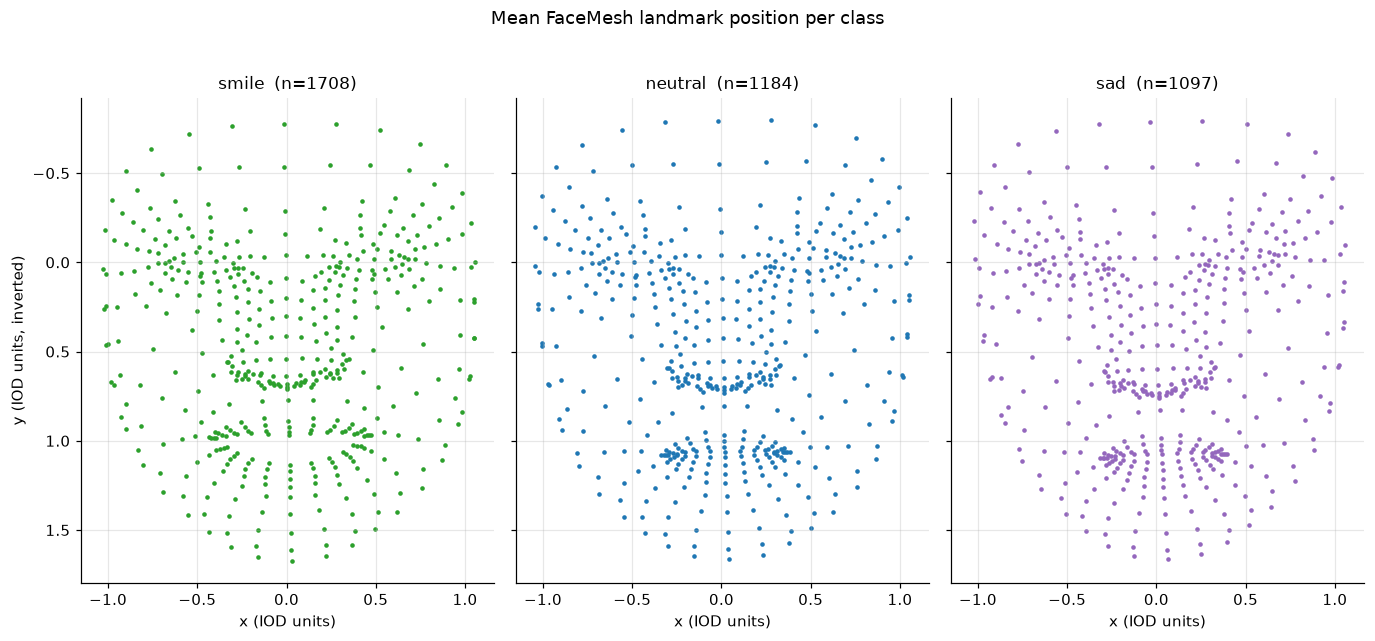

478 x-columns, 478 y-columns, classes: ['smile', 'neutral', 'sad']


In [15]:
# =============================================================================
# 13. Mean face per class — where the FaceMesh landmarks sit on average
# =============================================================================
x_cols = [c for c in landmarks.columns if c.startswith("x_")]
y_cols = ["y_" + c[2:] for c in x_cols]
lm_classes = [c for c in classes if c in set(landmarks["label"])]

if not x_cols or not lm_classes:
    print("landmark_features.csv has no coordinate columns / rows to plot")
else:
    means = {}
    for c in lm_classes:
        sub = landmarks.loc[landmarks["label"] == c, x_cols + y_cols]
        means[c] = (sub[x_cols].mean().values, sub[y_cols].mean().values, len(sub))

    def finite_span(values):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        return float(values.max() - values.min()) if values.size > 1 else 1.0

    # Size the panels from the data extent so the "equal" aspect does not waste space.
    span_x = finite_span(np.concatenate([m[0] for m in means.values()]))
    span_y = finite_span(np.concatenate([m[1] for m in means.values()]))
    panel_w = 4.2
    panel_h = float(np.clip(panel_w * span_y / span_x + 1.0, 2.4, 7.0))

    fig, axes = plt.subplots(1, len(lm_classes), figsize=(panel_w * len(lm_classes), panel_h),
                             sharex=True, sharey=True)
    for ax, c in zip(np.atleast_1d(axes), lm_classes):
        mean_x, mean_y, n_images = means[c]
        ax.scatter(mean_x, mean_y, s=4, color=label_color(c))
        ax.invert_yaxis()  # image coordinates: y grows downward
        ax.set_aspect("equal")
        ax.set_xlabel("x (IOD units)")
        ax.set_title(f"{c}  (n={n_images})")
    np.atleast_1d(axes)[0].set_ylabel("y (IOD units, inverted)")
    plt.suptitle("Mean FaceMesh landmark position per class")
    plt.tight_layout()
    save_fig(fig, "13_mean_landmark_face")

print(f"{len(x_cols)} x-columns, {len(y_cols)} y-columns, classes: {lm_classes}")


## 14. Which landmarks move between classes?

Instead of looking at the whole face, measure the Euclidean displacement of every landmark
from the **neutral mean shape** and show the 15 largest movers per class. For a 3-class FER
problem on frontal faces the list should be dominated by mouth-corner and lip landmarks
(FaceMesh 61/291/13/14/0/17); brow movers suggest the detector is compensating for pose,
which is a warning that some images are not frontal.


figure saved -> outputs\figures\14_landmark_shift_vs_neutral.png


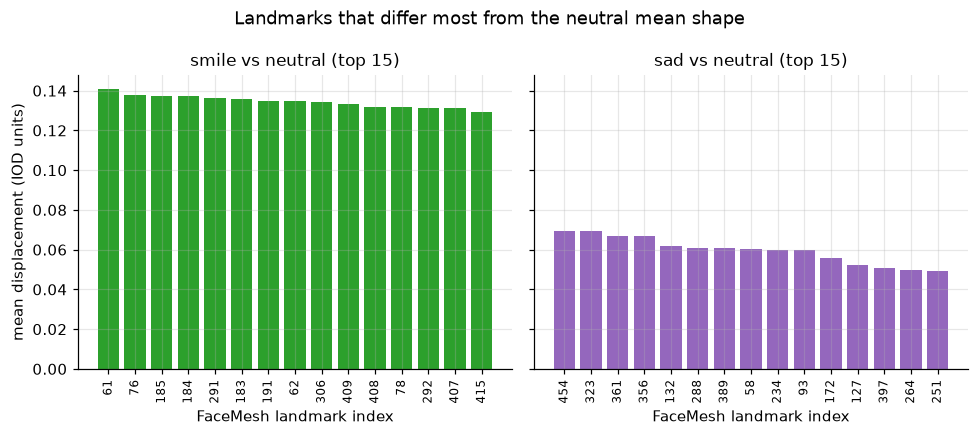

In [16]:
# =============================================================================
# 14. Which landmarks move? — mean displacement relative to the neutral mean shape
# =============================================================================
if not x_cols or "neutral" not in lm_classes:
    print("needs landmark columns plus a neutral class to compare against")
else:
    compare_classes = [c for c in lm_classes if c != "neutral"]
    neutral_x = landmarks.loc[landmarks["label"] == "neutral", x_cols].mean().values
    neutral_y = landmarks.loc[landmarks["label"] == "neutral", y_cols].mean().values
    landmark_ids = np.array([int(c[2:]) for c in x_cols])
    n_top = 15

    fig, axes = plt.subplots(1, len(compare_classes), figsize=(4.5 * len(compare_classes), 4),
                             sharey=True)
    for ax, c in zip(np.atleast_1d(axes), compare_classes):
        mean_x = landmarks.loc[landmarks["label"] == c, x_cols].mean().values
        mean_y = landmarks.loc[landmarks["label"] == c, y_cols].mean().values
        displacement = np.hypot(mean_x - neutral_x, mean_y - neutral_y)
        top = np.argsort(displacement)[::-1][:n_top]
        ax.bar(landmark_ids[top].astype(str), displacement[top], color=label_color(c))
        ax.set_title(f"{c} vs neutral (top {n_top})")
        ax.set_xlabel("FaceMesh landmark index")
        ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    np.atleast_1d(axes)[0].set_ylabel("mean displacement (IOD units)")
    plt.suptitle("Landmarks that differ most from the neutral mean shape")
    plt.tight_layout()
    save_fig(fig, "14_landmark_shift_vs_neutral")


## 15. Face scale and landmark completeness

* `iod_px` is the inter-ocular distance **in pixels** before normalization. It is the best
  proxy for "how many pixels does the face actually occupy". Very low values (say < 30 px)
  mean the geometry is quantized noise even though the image passed the 64 px gate; a
  large spread per source means the camera distance varied between sessions.
* The right panel counts landmark rows without any coordinate. Those are accepted images
  where FaceMesh found no face (`face_found=False`). They must be dropped in Scrub —
  the feature tables keep them visible on purpose (D10).


figure saved -> outputs\figures\15_scale_and_completeness.png


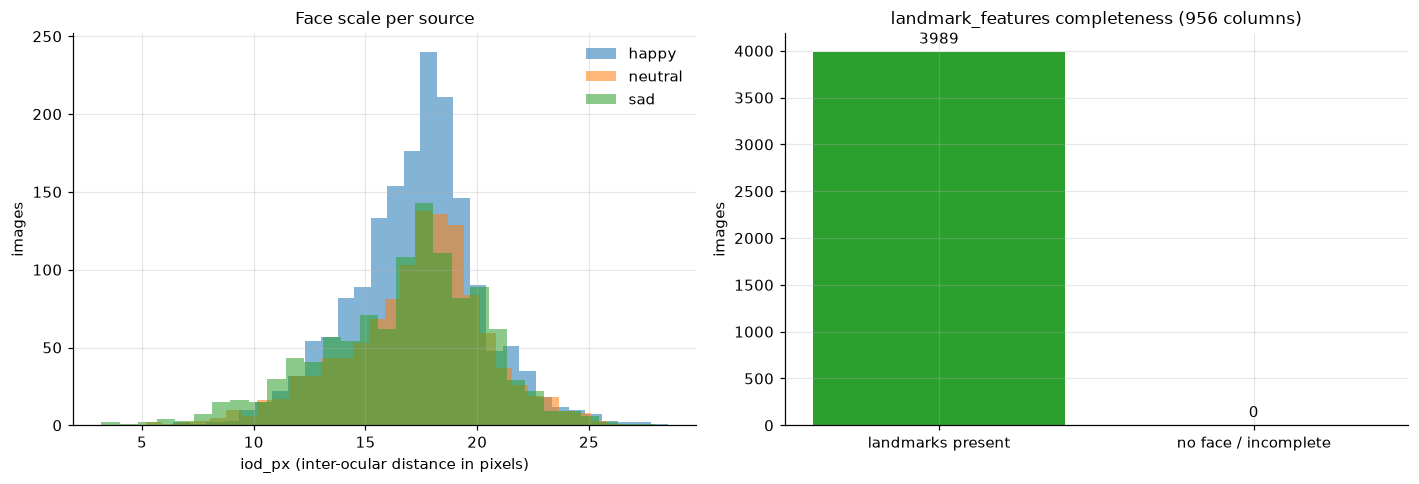

count    3989.00
mean       17.13
std         3.21
min         3.18
25%        15.36
50%        17.51
75%        19.06
max        28.53
Name: iod_px, dtype: float64

In [17]:
# =============================================================================
# 15. Scale (iod_px) and landmark completeness
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

if geo.empty:
    axes[0].text(0.5, 0.5, "no accepted geometric rows", ha="center", va="center",
                 transform=axes[0].transAxes)
    axes[0].set_axis_off()
else:
    for source, sub in geo.groupby("source", dropna=False):
        axes[0].hist(sub["iod_px"].dropna(), bins=30, alpha=0.55, label=str(source))
    axes[0].legend(frameon=False)
axes[0].set_xlabel("iod_px (inter-ocular distance in pixels)")
axes[0].set_ylabel("images")
axes[0].set_title("Face scale per source")

if x_cols:
    incomplete = landmarks[x_cols + y_cols].isna().any(axis=1)
    values = [int((~incomplete).sum()), int(incomplete.sum())]
else:
    values = [0, len(landmarks)]
bars = axes[1].bar(["landmarks present", "no face / incomplete"], values,
                   color=["#2ca02c", "#d62728"])
axes[1].bar_label(bars, padding=3)
axes[1].set_ylabel("images")
axes[1].set_title(f"landmark_features completeness ({len(x_cols) + len(y_cols)} columns)")

plt.tight_layout()
save_fig(fig, "15_scale_and_completeness")

geo["iod_px"].describe().round(2)


## 16. One-screen audit

The numbers worth quoting in a report or before starting Scrub, saved as
`outputs/figures/explore_audit.csv` next to the PNGs.


In [18]:
# =============================================================================
# 16. One-screen audit — numbers to quote before moving to Scrub
# =============================================================================
accepted_all = manifest.loc[manifest["accepted"]]
fer_only = accepted_all[accepted_all["label"].isin(CLASS_NAMES)]
class_counts = fer_only["label"].value_counts().reindex(list(CLASS_NAMES), fill_value=0)
imbalance = (class_counts.max() / class_counts.min()) if class_counts.min() > 0 else np.nan

audit = pd.Series({
    "images_found": len(manifest),
    "accepted": len(accepted_all),
    "rejected_%": round(100 * (~manifest["accepted"]).mean(), 1) if len(manifest) else 0.0,
    "face_detection_rate_%": (round(100 * accepted_all["face_found"].mean(), 1)
                              if len(accepted_all) else 0.0),
    "unlabeled_%": (round(100 * (accepted_all["label"] == UNLABELED).mean(), 1)
                    if len(accepted_all) else 0.0),
    "group_photos_(n_faces>1)": int((geo["n_faces"] > 1).sum()) if len(geo) else 0,
    "n_sources": int(accepted_all["source"].nunique(dropna=True)),
    "n_subjects": int(accepted_all["subject_id"].nunique(dropna=True)),
    "short_side_median_px": float(manifest["short_side"].median()) if len(manifest) else np.nan,
    "blur_median": float(manifest["blur_score"].median()) if len(manifest) else np.nan,
    "class_imbalance_max_over_min": (round(float(imbalance), 2)
                                     if np.isfinite(imbalance) else np.nan),
}, name="value")

audit_path = FIGURES_DIR / "explore_audit.csv"
audit.to_csv(audit_path)
print(f"saved -> {audit_path}")
print("class counts (accepted, FER classes only):")
print(class_counts.to_string())
audit


saved -> outputs\figures\explore_audit.csv
class counts (accepted, FER classes only):
label
smile      1708
neutral    1184
sad        1097


images_found                    4254.000000
accepted                        3989.000000
rejected_%                         6.200000
face_detection_rate_%            100.000000
unlabeled_%                        0.000000
group_photos_(n_faces>1)          14.000000
n_sources                          3.000000
n_subjects                         2.000000
short_side_median_px              48.000000
blur_median                     2001.513784
class_imbalance_max_over_min       1.560000
Name: value, dtype: float64

## 17. How to read the result / hand-off to Scrub

Checklist before starting the Scrub notebook:

* [ ] **Funnel** — is `face detected` close to `accepted`? Every image lost here is lost
      for the whole project. If the gap is large, look at pose and resolution of the
      failures in `manifest.csv`.
* [ ] **Label balance** — if `unlabeled` dominates, Obtain needs a labeling step before
      Scrub; if one class is far smaller, plan class weights or augmentation in Model.
* [ ] **Subject coverage** — with few subjects, split **by subject** in Scrub, otherwise
      accuracy will be flattered by face leakage.
* [ ] **Quality per class** — boxes that do not overlap mean the gates biased the classes;
      re-check the capture protocol before trusting any result.
* [ ] **Geometry** — `mouth_curvature` / `mouth_width` should separate smile from neutral.
      If they do not, go the CNN route on `crops/` (Obtain with `save_crops=True`).
* [ ] **Landmarks** — the biggest movers vs neutral should be lips/mouth corners. Brow
      movers imply non-frontal images; filter them by pose in Scrub.

**What this notebook deliberately does not do:** no cleaning, no imputation, no
train/val/test split, no model — that is the Scrub and Model stages. It only measures the
dataset Obtain produced.
